# 03 · Ingeniería de variables y dataset propuesto (JAE)

**Objetivo:** dejar listo el **dataset propuesto para entrenar distintos
modelos**, con hallazgos medidos con validación cruzada.

**Trabajo independiente:** esta propuesta se hace de forma independiente al
resto del equipo para después comparar hallazgos. Por eso el código vive en
su propio módulo, `src/features/engineering_jae.py` (con pruebas en
`tests/test_engineering_jae.py`), y no modifica el trabajo de nadie más.

**Insumos:** `notebooks/02_eda.ipynb` (sección 10) y
`docs/plan_ingenieria_variables.md`.

**Protocolo de evaluación (igual para todos los experimentos):**
- Validación cruzada estratificada de 5 pliegues, semilla 42, **mismos
  pliegues** para todos: las comparaciones son pareadas.
- Métrica: AUC-ROC.
- Modelo lineal: regresión logística (L2, `C=1`). Modelo de árboles:
  `HistGradientBoostingClassifier` con parámetros por omisión. Los
  hiperparámetros se ajustarán en la siguiente etapa; aquí solo se comparan
  variables.
- Todo lo que se aprende de los datos (medianas, cortes, WoE, escaladores)
  se ajusta **dentro de cada pliegue** con un `Pipeline`.

## 0. Preparación

In [1]:
import json
import logging
import sys
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# El notebook vive en notebooks/: se agrega src/ al path para importar el módulo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from features.engineering_jae import (  # noqa: E402
    AGE,
    DEBT_RATIO,
    ID,
    INCOME,
    LATE30,
    LATE60,
    LATE90,
    OPEN_LINES,
    RAW_FEATURES,
    REAL_ESTATE,
    DEPENDENTS,
    TARGET,
    UTIL,
    FeatureConfig,
    build_preprocessor,
    feature_groups,
    prepare_fixed,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("features").setLevel(logging.INFO)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

SALIDA = ROOT / "data" / "processed" / "jae"
SEMILLA = 42

train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
print(f"train: {train_raw.shape} · test: {test_raw.shape}")

train: (105000, 12) · test: (45000, 11)


## 1. Transformaciones fijas
Se aplican una sola vez, antes de la validación cruzada, porque no aprenden
nada de los datos. Como en el EDA, **no se elimina ninguna fila** (no hay
`Id` repetidos).

In [2]:
y = train_raw[TARGET]
X = prepare_fixed(train_raw.drop(columns=[TARGET, ID]))
X_test = prepare_fixed(test_raw.drop(columns=[ID]))

# Cifras de control de la limpieza fija
control_fijo = pd.DataFrame(
    {
        "train": [
            len(train_raw),
            len(X),
            X["late_sentinel"].sum(),
            X["income_missing"].sum(),
            X["income_zero"].sum(),
            X["dependents_missing"].sum(),
            X[AGE].isna().sum(),
            X["util_gt1"].sum(),
            X["util_zero"].sum(),
            X["thin_file"].sum(),
        ],
        "test": [
            len(test_raw),
            len(X_test),
            X_test["late_sentinel"].sum(),
            X_test["income_missing"].sum(),
            X_test["income_zero"].sum(),
            X_test["dependents_missing"].sum(),
            X_test[AGE].isna().sum(),
            X_test["util_gt1"].sum(),
            X_test["util_zero"].sum(),
            X_test["thin_file"].sum(),
        ],
    },
    index=[
        "filas de entrada",
        "filas de salida",
        "códigos 96/98 (late_sentinel)",
        "ingreso faltante",
        "ingreso = 0",
        "dependientes faltantes",
        "edad inválida (< 18)",
        "utilización > 1",
        "utilización = 0",
        "expediente delgado",
    ],
)
assert len(X) == len(train_raw) and len(X_test) == len(
    test_raw
), "Cambió el número de filas"
control_fijo

INFO features.engineering_jae: Limpieza fija: 105000 filas, 197 con códigos 96/98, 1 edades inválidas


INFO features.engineering_jae: Variables fijas agregadas: 35 columnas en total


INFO features.engineering_jae: Limpieza fija: 45000 filas, 72 con códigos 96/98, 0 edades inválidas


INFO features.engineering_jae: Variables fijas agregadas: 35 columnas en total


,train,test
filas de entrada,105000,45000
filas de salida,105000,45000
códigos 96/98 (late_sentinel),197,72
ingreso faltante,20828,8903
ingreso = 0,1143,491
dependientes faltantes,2771,1153
edad inválida (< 18),1,0
utilización > 1,2316,1005
utilización = 0,7652,3226
expediente delgado,316,141


### Catálogo de variables construidas

In [3]:
CATALOGO = {
    "util_clip": "Utilización recortada a [0, 2]",
    "util_gt1": "1 si la utilización supera 1",
    "util_zero": "1 si la utilización es 0",
    "late_30_59 / late_60_89 / late_90": "Atrasos sin códigos 96/98, recortados a 6",
    "late_sentinel": "1 si la fila tenía códigos 96/98",
    "total_late": "Suma de los tres atrasos",
    "late_severity": "30–59 + 2 × 60–89 + 3 × 90+",
    "thin_file": "Sin atrasos, sin utilización y ≤ 1 línea abierta",
    "debt_amount": "Monto mensual de deuda (razón × ingreso, o DebtRatio si no hay ingreso)",
    "debt_ratio_valid": "DebtRatio solo con ingreso > 0, recortado a 10 (0 si no aplica)",
    "income_clip": "Ingreso recortado a 25,000 (con faltantes)",
    "income_imp_age_mortgage": "⭐ A: ingreso imputado por edad + n.º de créditos hipotecarios",
    "income_imp_age_debt": "🔷 B: ingreso imputado por edad + decil del monto de deuda",
    "disposable_<ingreso>": "Ingreso disponible = ingreso imputado − monto de deuda",
    "income_missing / income_zero / dependents_missing": "Indicadores de faltante o cero",
    "open_lines / real_estate / dependents": "Recortados a 24 / 5 / 5",
    "age_group / mortgage_level": "Llaves de grupo para imputar (no entran al modelo)",
}
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(CATALOGO, name="descripción").to_frame())

,descripción
util_clip,"Utilización recortada a [0, 2]"
util_gt1,1 si la utilización supera 1
util_zero,1 si la utilización es 0
late_30_59 / late_60_89 / late_90,"Atrasos sin códigos 96/98, recortados a 6"
late_sentinel,1 si la fila tenía códigos 96/98
total_late,Suma de los tres atrasos
late_severity,30–59 + 2 × 60–89 + 3 × 90+
thin_file,"Sin atrasos, sin utilización y ≤ 1 línea abierta"
debt_amount,"Monto mensual de deuda (razón × ingreso, o DebtRatio si no hay ingreso)"
debt_ratio_valid,"DebtRatio solo con ingreso > 0, recortado a 10 (0 si no aplica)"


## 2. Herramientas de evaluación

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
resultados: list[dict] = []
puntajes: dict[str, np.ndarray] = {}


def evaluar(
    nombre: str, grupo: str, modelo: Pipeline, datos: pd.DataFrame = X
) -> np.ndarray:
    """Evalúa un pipeline con validación cruzada y guarda el resultado.

    Args:
        nombre: Nombre del experimento.
        grupo: Grupo de experimentos al que pertenece.
        modelo: Pipeline completo (preprocesamiento + modelo).
        datos: Variables de entrada.

    Returns:
        AUC de cada pliegue.
    """
    auc = cross_val_score(modelo, datos, y, cv=CV, scoring="roc_auc")
    puntajes[nombre] = auc
    resultados.append(
        {"grupo": grupo, "experimento": nombre, "AUC": auc.mean(), "desv": auc.std()}
    )
    return auc


def sin_emojis(textos: pd.Index | list[str]) -> list[str]:
    """Quita ⭐ y 🔷 de las etiquetas (matplotlib no tiene esos glifos)."""
    return [t.replace("⭐ ", "").replace("🔷 ", "") for t in textos]


def logistica(config: FeatureConfig) -> Pipeline:
    """Pipeline de preprocesamiento JAE + regresión logística."""
    return make_pipeline(build_preprocessor(config), LogisticRegression(max_iter=2000))


def arboles(config: FeatureConfig) -> Pipeline:
    """Pipeline de preprocesamiento JAE + HistGradientBoosting."""
    return make_pipeline(
        build_preprocessor(config), HistGradientBoostingClassifier(random_state=SEMILLA)
    )


def comparar(base: str, variantes: list[str]) -> pd.DataFrame:
    """Compara variantes contra una base, pliegue por pliegue.

    Args:
        base: Experimento de referencia.
        variantes: Experimentos a comparar.

    Returns:
        Tabla con AUC, diferencia promedio y pliegues en que gana la variante.
    """
    filas = []
    for nombre in variantes:
        diferencia = puntajes[nombre] - puntajes[base]
        filas.append(
            {
                "experimento": nombre,
                "AUC": puntajes[nombre].mean(),
                "desv": puntajes[nombre].std(),
                f"diferencia vs {base}": diferencia.mean(),
                "pliegues en que gana": f"{int((diferencia > 0).sum())}/5",
            }
        )
    return pd.DataFrame(filas).set_index("experimento").round(4)

## 3. ¿Cuánto aporta la ingeniería de variables? (escalera)
Partimos de las variables **crudas** y agregamos un paso a la vez. Así se ve
qué decisión del EDA mueve realmente el AUC de la regresión logística.

,AUC,desv,aporte del paso,pliegues en que mejora
1. variables crudas,0.6996,0.0036,NaN,—
2. + códigos 96/98 corregidos,0.8137,0.0073,0.1141,5/5
3. + recortes de atípicos,0.8508,0.0070,0.0371,5/5
4. + DebtRatio separado e indicadores,0.8508,0.0068,0.0000,4/5
5. + log1p,0.8555,0.0069,0.0047,5/5
"6. + imputación ⭐ A, ingreso disponible y perfil (propuesta)",0.8565,0.0068,0.0010,5/5


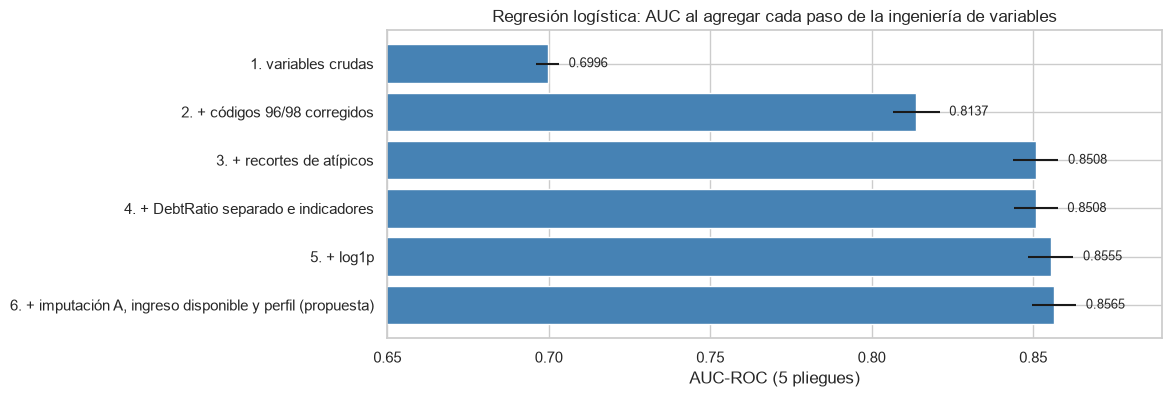

In [5]:
def logistica_columnas(
    log: list[str] | None = None,
    plain: list[str] | None = None,
    flags: list[str] | None = None,
) -> Pipeline:
    """Regresión logística sobre columnas elegidas (mediana → [log1p] → escalar).

    Args:
        log: Columnas que reciben ``log1p`` antes de escalar.
        plain: Columnas que solo se escalan.
        flags: Indicadores que pasan sin cambio.

    Returns:
        Pipeline completo.
    """
    ramas = []
    if log:
        ramas.append(
            (
                "log",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="median")),
                        ("log", FunctionTransformer(np.log1p)),
                        ("scale", StandardScaler()),
                    ]
                ),
                log,
            )
        )
    if plain:
        ramas.append(
            (
                "plain",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                plain,
            )
        )
    if flags:
        ramas.append(("flags", "passthrough", flags))
    return make_pipeline(ColumnTransformer(ramas), LogisticRegression(max_iter=2000))


# Para la escalera se necesitan también las columnas crudas
X_escalera = X.copy()
for col in [
    UTIL,
    AGE,
    LATE30,
    LATE60,
    LATE90,
    DEBT_RATIO,
    INCOME,
    OPEN_LINES,
    REAL_ESTATE,
    DEPENDENTS,
]:
    X_escalera[f"{col}__crudo"] = train_raw[col]

ATRASOS = ["late_30_59", "late_60_89", "late_90"]
INDICADORES_BASE = [
    "late_sentinel",
    "util_gt1",
    "income_missing",
    "income_zero",
    "dependents_missing",
]
CRUDAS = [f"{c}__crudo" for c in RAW_FEATURES]
RESTO_CRUDAS = [
    f"{c}__crudo" for c in RAW_FEATURES if c not in (LATE30, LATE60, LATE90)
]
RECORTADAS = [
    "util_clip",
    AGE,
    "income_clip",
    "open_lines",
    "real_estate",
    "dependents",
]

escalera = {
    "1. variables crudas": logistica_columnas(plain=CRUDAS),
    "2. + códigos 96/98 corregidos": logistica_columnas(
        plain=RESTO_CRUDAS + ATRASOS, flags=["late_sentinel"]
    ),
    "3. + recortes de atípicos": logistica_columnas(
        plain=RECORTADAS + [f"{DEBT_RATIO}__crudo"] + ATRASOS,
        flags=["late_sentinel", "util_gt1"],
    ),
    "4. + DebtRatio separado e indicadores": logistica_columnas(
        plain=RECORTADAS + ["debt_ratio_valid", "debt_amount"] + ATRASOS,
        flags=INDICADORES_BASE,
    ),
    "5. + log1p": logistica_columnas(
        log=["income_clip", "debt_ratio_valid", "debt_amount"] + ATRASOS,
        plain=["util_clip", AGE, "open_lines", "real_estate", "dependents"],
        flags=INDICADORES_BASE,
    ),
    "6. + imputación ⭐ A, ingreso disponible y perfil (propuesta)": logistica(
        FeatureConfig()
    ),
}
for nombre, modelo in escalera.items():
    evaluar(nombre, "escalera", modelo, X_escalera)

tabla_escalera = pd.DataFrame(
    {
        "AUC": {k: puntajes[k].mean() for k in escalera},
        "desv": {k: puntajes[k].std() for k in escalera},
    }
)
tabla_escalera["aporte del paso"] = tabla_escalera["AUC"].diff()
nombres = list(escalera)
tabla_escalera["pliegues en que mejora"] = ["—"] + [
    f"{int((puntajes[b] > puntajes[a]).sum())}/5" for a, b in zip(nombres, nombres[1:])
]
display(tabla_escalera.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(
    sin_emojis(tabla_escalera.index),
    tabla_escalera["AUC"],
    color="steelblue",
    xerr=tabla_escalera["desv"],
)
ax.set_xlim(0.65, 0.89)
ax.invert_yaxis()
for i, (v, d) in enumerate(zip(tabla_escalera["AUC"], tabla_escalera["desv"])):
    ax.text(v + d + 0.003, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_title(
    "Regresión logística: AUC al agregar cada paso de la ingeniería de variables"
)
ax.set_xlabel("AUC-ROC (5 pliegues)")
plt.show()

**Lectura: la limpieza pesa mucho más que las variables sofisticadas.**
- Con las variables crudas, la regresión logística apenas llega a **0.700**.
- **Corregir los códigos 96/98 aporta +0.114 por sí solo** (0.700 → 0.814).
  En crudo, esos 197 registros tienen "96 atrasos", un valor enorme que
  distorsiona los coeficientes de las tres variables de atraso.
- **Recortar atípicos aporta +0.037** (utilización > 2, ingresos extremos,
  etc.).
- Separar `DebtRatio` no mueve el AUC de la regresión logística (0.0000), pero
  es necesario para calcular el monto de deuda, la imputación 🔷 B y el
  ingreso disponible.
- `log1p` aporta +0.005 y la propuesta completa +0.001 más, en los 5
  pliegues.
- **Total: +0.157 de AUC; el 95 % viene de los dos primeros pasos de
  limpieza.**

## 4. Experimentos con regresión logística
Base: la propuesta completa (paso 6). Cada experimento cambia **una sola
decisión** y se compara pliegue por pliegue contra la base.

In [6]:
BASE = FeatureConfig()
NOMBRE_BASE = "base: ⭐ A · Standard · conteo · escaladas · disponible · perfil"
evaluar(NOMBRE_BASE, "lineal", logistica(BASE))

experimentos_lineales = {
    "imputación de ingreso": {
        "ingreso: mediana global": replace(BASE, income_strategy="global"),
        "ingreso: 🔷 B (edad + deuda)": replace(BASE, income_strategy="B"),
        "ingreso: ⭐ A + 🔷 B (ambas)": replace(BASE, income_strategy="AB"),
    },
    "escalado": {
        "escalado: RobustScaler": replace(BASE, scaler="robust"),
        "escalado: QuantileTransformer": replace(BASE, scaler="quantile"),
    },
    "atrasos": {
        "atrasos: binarizados": replace(BASE, late_mode="binary"),
    },
    "representación": {
        "representación: WoE": replace(BASE, representation="woe"),
        "representación: splines (utilización y edad)": replace(
            BASE, representation="splines"
        ),
    },
    "variables nuevas": {
        "sin ingreso disponible": replace(BASE, disposable_income=False),
        "sin indicadores de perfil": replace(BASE, profile_flags=False),
        "sin ingreso disponible ni perfil": replace(
            BASE, disposable_income=False, profile_flags=False
        ),
    },
}
for grupo, variantes in experimentos_lineales.items():
    for nombre, config in variantes.items():
        evaluar(nombre, grupo, logistica(config))
    print(f"\n### {grupo}")
    display(comparar(NOMBRE_BASE, list(variantes)))


### imputación de ingreso


,AUC,desv,diferencia vs base: ⭐ A · Standard · conteo · escaladas · disponible · perfil,pliegues en que gana
experimento,,,,
ingreso: mediana global,0.8564,0.0067,-0.0001,0/5
ingreso: 🔷 B (edad + deuda),0.8565,0.0068,-0.0001,2/5
ingreso: ⭐ A + 🔷 B (ambas),0.8564,0.0068,-0.0001,2/5



### escalado


,AUC,desv,diferencia vs base: ⭐ A · Standard · conteo · escaladas · disponible · perfil,pliegues en que gana
experimento,,,,
escalado: RobustScaler,0.8565,0.0067,0.0000,3/5
escalado: QuantileTransformer,0.8553,0.0077,-0.0013,0/5



### atrasos


,AUC,desv,diferencia vs base: ⭐ A · Standard · conteo · escaladas · disponible · perfil,pliegues en que gana
experimento,,,,
atrasos: binarizados,0.8564,0.0069,-0.0001,3/5



### representación


,AUC,desv,diferencia vs base: ⭐ A · Standard · conteo · escaladas · disponible · perfil,pliegues en que gana
experimento,,,,
representación: WoE,0.8568,0.0074,0.0003,3/5
representación: splines (utilización y edad),0.8565,0.0064,0.0000,2/5



### variables nuevas


,AUC,desv,diferencia vs base: ⭐ A · Standard · conteo · escaladas · disponible · perfil,pliegues en que gana
experimento,,,,
sin ingreso disponible,0.8559,0.0067,-0.0007,0/5
sin indicadores de perfil,0.8561,0.0070,-0.0004,1/5
sin ingreso disponible ni perfil,0.8555,0.0069,-0.0010,0/5


**Lectura** (las diferencias se comparan pliegue por pliegue; la desviación
entre pliegues es ~0.007, así que diferencias < 0.001 solo cuentan si son
consistentes en casi todos los pliegues):
- **Imputación del ingreso:** las cuatro estrategias empatan (diferencias
  ≤ 0.0001). El ingreso es una variable débil (IV 0.08), así que imputarlo
  mejor casi no cambia el AUC. Se elige **⭐ A por ser la más fácil de
  explicar**; 🔷 B queda en el dataset para quien quiera probarla.
- **Escalado:** `StandardScaler` y `RobustScaler` empatan;
  `QuantileTransformer` es peor (−0.0013, pierde en los 5 pliegues).
- **Atrasos binarizados:** empate (−0.0001). Se conserva el conteo.
- **WoE** (+0.0003, gana 3/5) y ***splines*** (0.0000): sin mejora
  significativa. Con la limpieza y `log1p`, la regresión logística ya capta
  casi toda la señal. WoE sigue siendo útil si se quiere una tarjeta de
  puntaje (*scorecard*) interpretable.
- **Variables nuevas:** quitar el ingreso disponible cuesta −0.0007 (la base
  gana 5/5); quitar los indicadores de perfil, −0.0004 (4/5); quitar ambos,
  −0.0010 (5/5). **Es poco, pero consistente: se conservan.**

## 5. Experimentos con árboles (`HistGradientBoostingClassifier`)

In [7]:
BASE_ARBOLES = FeatureConfig(for_trees=True)
NOMBRE_BASE_ARBOLES = "árboles base: ⭐ A imputado · disponible · perfil"
evaluar(
    "árboles: variables crudas",
    "árboles",
    make_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA)),
    X_escalera[CRUDAS],
)
evaluar(NOMBRE_BASE_ARBOLES, "árboles", arboles(BASE_ARBOLES))

experimentos_arboles = {
    "árboles: sin imputar (NaN nativo)": replace(BASE_ARBOLES, impute_for_trees=False),
    "árboles: ingreso 🔷 B": replace(BASE_ARBOLES, income_strategy="B"),
    "árboles: ingreso ⭐ A + 🔷 B": replace(BASE_ARBOLES, income_strategy="AB"),
    "árboles: sin ingreso disponible": replace(BASE_ARBOLES, disposable_income=False),
    "árboles: sin indicadores de perfil": replace(BASE_ARBOLES, profile_flags=False),
}
for nombre, config in experimentos_arboles.items():
    evaluar(nombre, "árboles", arboles(config))
comparar(NOMBRE_BASE_ARBOLES, ["árboles: variables crudas", *experimentos_arboles])

,AUC,desv,diferencia vs árboles base: ⭐ A imputado · disponible · perfil,pliegues en que gana
experimento,,,,
árboles: variables crudas,0.8622,0.0071,-0.0007,1/5
árboles: sin imputar (NaN nativo),0.8628,0.0079,-0.0001,2/5
árboles: ingreso 🔷 B,0.8626,0.0075,-0.0003,2/5
árboles: ingreso ⭐ A + 🔷 B,0.8627,0.0067,-0.0002,1/5
árboles: sin ingreso disponible,0.8631,0.0067,0.0002,2/5
árboles: sin indicadores de perfil,0.8630,0.0070,0.0001,3/5


**Lectura:**
- Los árboles con variables **crudas** ya logran **0.8622**: son robustos a
  atípicos y a los códigos 96/98. La ingeniería de variables solo suma
  +0.0007 (0.8629).
- Imputar o dejar `NaN`, usar ⭐ A o 🔷 B, e incluir o no el ingreso
  disponible o los indicadores de perfil: todas las diferencias están dentro
  de ±0.0003, sin un patrón consistente entre pliegues.
- Los árboles superan a la mejor regresión logística por ~0.006 (0.8629
  contra 0.8568). Para los árboles, las mejoras vendrán de los
  hiperparámetros y de combinar modelos, no de más variables.

## 6. Todos los experimentos

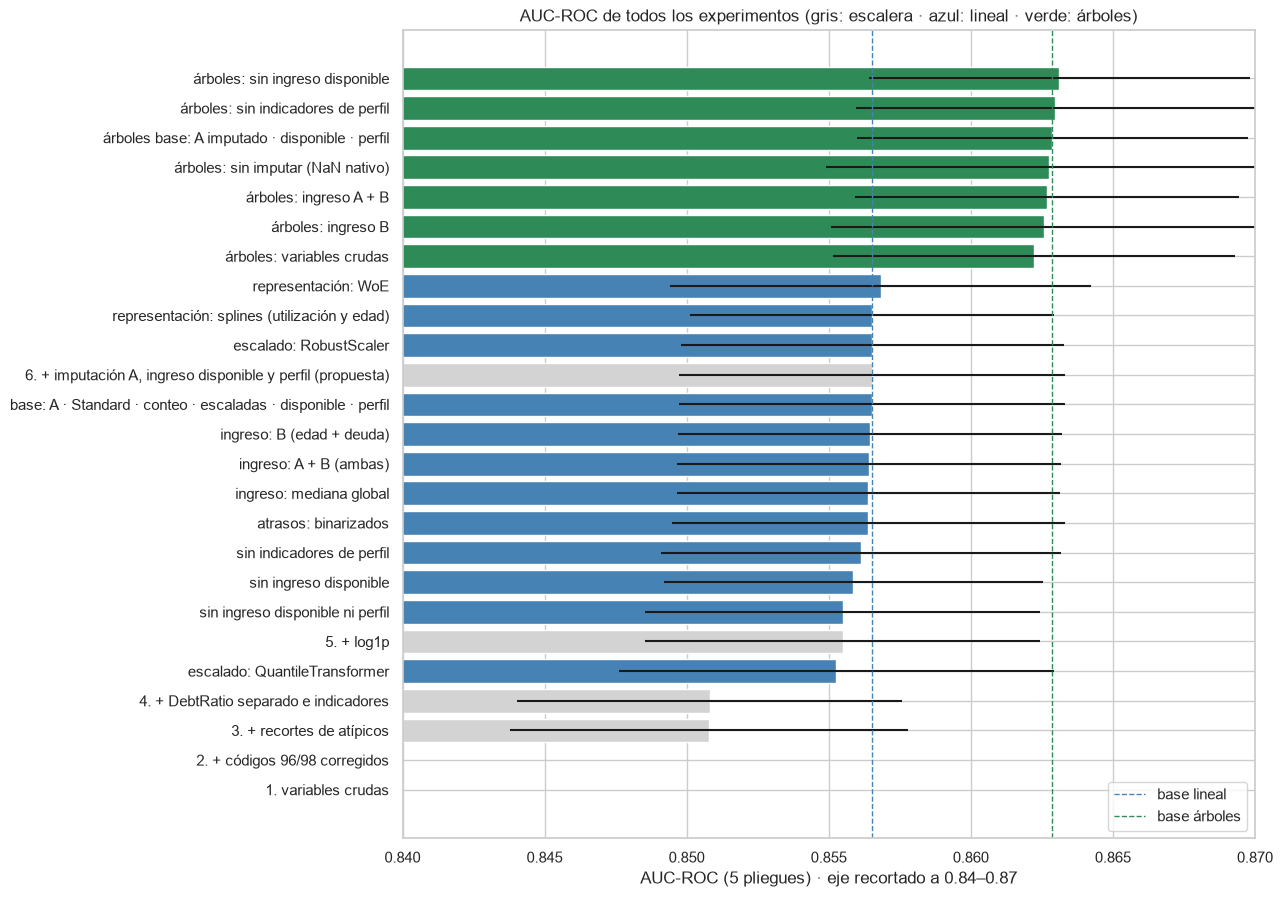

,grupo,AUC,desv
experimento,,,
1. variables crudas,escalera,0.6996,0.0036
2. + códigos 96/98 corregidos,escalera,0.8137,0.0073
3. + recortes de atípicos,escalera,0.8508,0.0070
4. + DebtRatio separado e indicadores,escalera,0.8508,0.0068
escalado: QuantileTransformer,escalado,0.8553,0.0077
5. + log1p,escalera,0.8555,0.0069
sin ingreso disponible ni perfil,variables nuevas,0.8555,0.0069
sin ingreso disponible,variables nuevas,0.8559,0.0067
sin indicadores de perfil,variables nuevas,0.8561,0.0070


In [8]:
tabla_resultados = pd.DataFrame(resultados).sort_values("AUC")
fig, ax = plt.subplots(figsize=(11, 0.38 * len(tabla_resultados) + 1))
colores = {"escalera": "lightgray", "árboles": "seagreen"}
ax.barh(
    sin_emojis(tabla_resultados["experimento"]),
    tabla_resultados["AUC"],
    xerr=tabla_resultados["desv"],
    color=[colores.get(g, "steelblue") for g in tabla_resultados["grupo"]],
)
ax.set_xlim(0.84, 0.87)
ax.axvline(
    puntajes[NOMBRE_BASE].mean(), color="steelblue", ls="--", lw=1, label="base lineal"
)
ax.axvline(
    puntajes[NOMBRE_BASE_ARBOLES].mean(),
    color="seagreen",
    ls="--",
    lw=1,
    label="base árboles",
)
ax.set_title(
    "AUC-ROC de todos los experimentos (gris: escalera · azul: lineal · verde: árboles)"
)
ax.set_xlabel("AUC-ROC (5 pliegues) · eje recortado a 0.84–0.87")
ax.legend(loc="lower right")
plt.show()
tabla_resultados.set_index("experimento").round(4)

## 7. ¿Qué variables usa cada modelo?

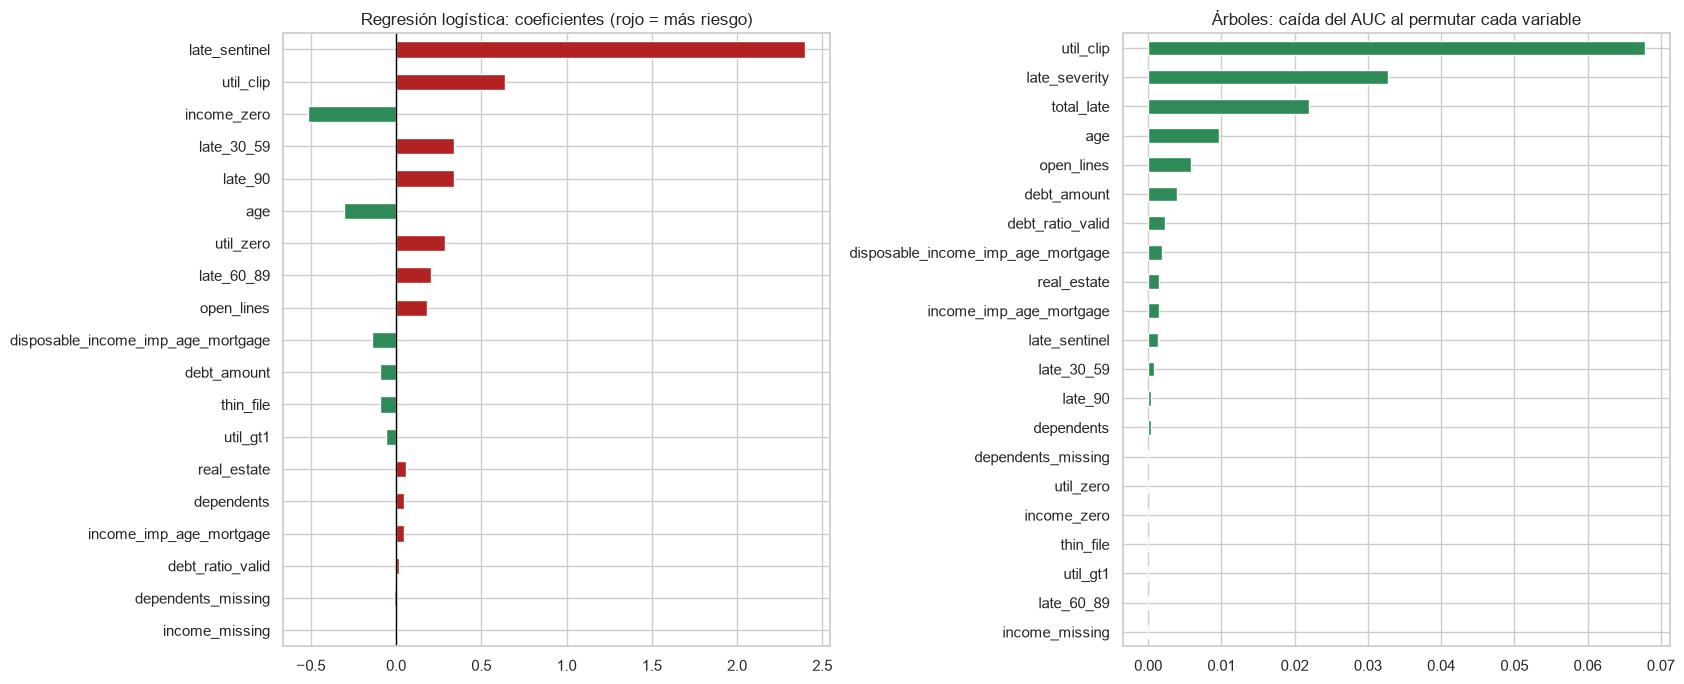

In [9]:
# Regresión logística: coeficientes del modelo base (variables estandarizadas)
modelo_lineal = logistica(BASE).fit(X, y)
nombres_lineal = modelo_lineal[:-1].transform(X.head()).columns
coeficientes = pd.Series(modelo_lineal[-1].coef_[0], index=nombres_lineal)
coeficientes = coeficientes.reindex(coeficientes.abs().sort_values().index)

# Árboles: importancia por permutación en un 20 % reservado
X_aj, X_res, y_aj, y_res = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)
modelo_arboles = arboles(BASE_ARBOLES).fit(X_aj, y_aj)
X_res_t = modelo_arboles[:-1].transform(X_res)
importancia = permutation_importance(
    modelo_arboles[-1],
    X_res_t,
    y_res,
    scoring="roc_auc",
    n_repeats=5,
    random_state=SEMILLA,
)
importancia_arboles = pd.Series(importancia.importances_mean, index=X_res_t.columns)
importancia_arboles = importancia_arboles.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
coeficientes.plot(
    kind="barh",
    ax=axes[0],
    color=["firebrick" if c > 0 else "seagreen" for c in coeficientes],
)
axes[0].set_title("Regresión logística: coeficientes (rojo = más riesgo)")
axes[0].axvline(0, color="black", lw=1)
importancia_arboles.plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Árboles: caída del AUC al permutar cada variable")
plt.tight_layout()
plt.show()

**Lectura:**
- **Regresión logística:** el coeficiente más grande es `late_sentinel`
  (+2.4): tener códigos 96/98 es una señal de riesgo muy fuerte. Siguen la
  utilización (+0.63) y los atrasos. La edad, el ingreso disponible y
  `thin_file` reducen el riesgo. Dos signos llamativos: `income_zero`
  reduce el riesgo, y `util_zero` lo aumenta *una vez que se consideran las
  demás variables* (coincide con el WoE del EDA: utilización 0 es menos
  segura que 0–0.1). Los coeficientes son condicionales y las variables
  están correlacionadas, así que se interpretan con cuidado.
- **Árboles:** la utilización domina (permutarla baja el AUC 0.068), seguida
  de `late_severity`, `total_late`, la edad y las líneas abiertas. Las
  variables de ingreso aportan poco y los indicadores casi nada (los árboles
  los deducen de las variables originales).
- **Ambos modelos coinciden con el PCA del EDA:** utilización + atrasos +
  edad son el corazón del problema; el jugo en los datos está ahí.

## 8. Dataset propuesto

**Configuración elegida:**

| | Modelos lineales | Modelos de árboles |
| --- | --- | --- |
| Ingreso | ⭐ A: edad + n.º de créditos hipotecarios | ⭐ A (imputado) |
| Escalado | `log1p` + `StandardScaler` | Ninguno |
| Atrasos | Conteo recortado + `log1p` | Conteo recortado |
| Variables nuevas | Ingreso disponible + `util_zero` + `thin_file` | Igual |

**Qué se guarda:** un solo dataset **sin escalar** con todas las variables
construidas, incluidas las dos versiones del ingreso (⭐ A y 🔷 B), para
que cada integrante pueda probar las suyas. Las imputaciones se ajustan con
**todo `train`** y se aplican a `test` (así se usa en el entrenamiento
final). Para validación cruzada rigurosa, usar `build_preprocessor` dentro
del pipeline, como en este notebook.

Junto al dataset se guarda `features_jae.json` con las listas de columnas
recomendadas para cada tipo de modelo.

In [10]:
config_dataset = FeatureConfig(for_trees=True, income_strategy="AB")
preprocesador_dataset = build_preprocessor(config_dataset).fit(X, y)
dataset_train = preprocesador_dataset.transform(X)
dataset_test = preprocesador_dataset.transform(X_test)

dataset_train.insert(0, ID, train_raw[ID].to_numpy())
dataset_train[TARGET] = y.to_numpy()
dataset_test.insert(0, ID, test_raw[ID].to_numpy())

# Reglas de calidad (DQ) y cifras de control
columnas_modelo = [c for c in dataset_train.columns if c not in (ID, TARGET)]
assert len(dataset_train) == len(train_raw), "train cambió de tamaño"
assert len(dataset_test) == len(test_raw), "test cambió de tamaño"
assert dataset_train[ID].is_unique and dataset_test[ID].is_unique, "Id repetidos"
assert list(dataset_test.columns) == [ID, *columnas_modelo], "train y test no coinciden"
assert not np.isinf(dataset_train[columnas_modelo].to_numpy()).any(), "Hay infinitos"
faltantes_permitidos = {AGE}  # edad < 18: los pipelines lineales la imputan
faltantes = {
    c
    for c in columnas_modelo
    if dataset_train[c].isna().any() or dataset_test[c].isna().any()
}
assert faltantes <= faltantes_permitidos, f"Faltantes inesperados: {faltantes}"

cifras_dataset = pd.DataFrame(
    {
        "train": [
            f"{len(dataset_train):,}",
            len(columnas_modelo),
            int(dataset_train[columnas_modelo].isna().sum().sum()),
            f"{dataset_train[TARGET].mean():.4f}",
        ],
        "test": [
            f"{len(dataset_test):,}",
            len(columnas_modelo),
            int(dataset_test[columnas_modelo].isna().sum().sum()),
            "—",
        ],
    },
    index=["filas", "variables", "valores faltantes", "tasa de morosidad"],
)
display(cifras_dataset)
print("Variables del dataset propuesto:", columnas_modelo)

,train,test
filas,"105,000","45,000"
variables,23,23
valores faltantes,1,0
tasa de morosidad,0.0668,—


Variables del dataset propuesto: ['income_imp_age_mortgage', 'income_imp_age_debt', 'debt_amount', 'debt_ratio_valid', 'late_30_59', 'late_60_89', 'late_90', 'disposable_income_imp_age_mortgage', 'disposable_income_imp_age_debt', 'util_clip', 'age', 'open_lines', 'real_estate', 'dependents', 'late_sentinel', 'income_missing', 'income_zero', 'dependents_missing', 'util_gt1', 'util_zero', 'thin_file', 'total_late', 'late_severity']


In [11]:
grupos_lineal = feature_groups(BASE)
especificacion = {
    "descripcion": "Dataset propuesto JAE (notebooks/03_ingenieria_variables_jae)",
    "id": ID,
    "objetivo": TARGET,
    "columnas": columnas_modelo,
    "lineal": {
        "config": asdict(BASE),
        "log1p_y_estandarizar": grupos_lineal["log"],
        "log_con_signo_y_estandarizar": grupos_lineal["signed_log"],
        "estandarizar": grupos_lineal["plain"],
        "indicadores_sin_cambio": grupos_lineal["flags"],
        "nota": "Imputar edad con la mediana; usar build_preprocessor en CV.",
    },
    "arboles": {
        "config": asdict(BASE_ARBOLES),
        "columnas": [
            c
            for c in columnas_modelo
            if c not in ("income_imp_age_debt", "disposable_income_imp_age_debt")
        ],
    },
    "auc_cv_5_pliegues": {
        "lineal_base": round(float(puntajes[NOMBRE_BASE].mean()), 4),
        "arboles_base": round(float(puntajes[NOMBRE_BASE_ARBOLES].mean()), 4),
    },
}

SALIDA.mkdir(parents=True, exist_ok=True)
dataset_train.to_parquet(SALIDA / "train_jae.parquet", index=False)
dataset_test.to_parquet(SALIDA / "test_jae.parquet", index=False)
(SALIDA / "features_jae.json").write_text(
    json.dumps(especificacion, ensure_ascii=False, indent=2), encoding="utf-8"
)
for archivo in sorted(SALIDA.iterdir()):
    print(f"✅ {archivo.relative_to(ROOT)} ({archivo.stat().st_size / 1e6:.1f} MB)")

✅ data/processed/jae/features_jae.json (0.0 MB)
✅ data/processed/jae/test_jae.parquet (2.6 MB)
✅ data/processed/jae/train_jae.parquet (6.0 MB)


### Verificación: el dataset guardado reproduce el AUC
Se vuelve a leer el archivo y se entrena con las columnas recomendadas. Como
las imputaciones se ajustaron con todo `train`, el AUC puede quedar
ligeramente por encima del obtenido con el pipeline dentro de cada pliegue.

In [12]:
leido = pd.read_parquet(SALIDA / "train_jae.parquet")
X_leido = leido[especificacion["arboles"]["columnas"]]
auc_leido = cross_val_score(
    HistGradientBoostingClassifier(random_state=SEMILLA),
    X_leido,
    leido[TARGET],
    cv=CV,
    scoring="roc_auc",
)
print(
    f"Árboles sobre el dataset guardado: AUC {auc_leido.mean():.4f} ± {auc_leido.std():.4f}"
)
print(
    f"Árboles con pipeline en cada pliegue: AUC {puntajes[NOMBRE_BASE_ARBOLES].mean():.4f}"
)

Árboles sobre el dataset guardado: AUC 0.8631 ± 0.0070
Árboles con pipeline en cada pliegue: AUC 0.8629


## 9. Hallazgos para comparar con el equipo

| # | Hallazgo | Evidencia |
| --- | --- | --- |
| 1 | **La limpieza pesa más que las variables nuevas** en modelos lineales | Códigos 96/98: +0.114; recortes: +0.037; todo lo demás: +0.006 |
| 2 | **Los árboles casi no necesitan ingeniería de variables** | 0.8622 crudas contra 0.8629 con la propuesta |
| 3 | Los árboles superan a la regresión logística | 0.8629 contra 0.8568 (mejor variante lineal) |
| 4 | La estrategia de imputación del ingreso no cambia el AUC | Global, ⭐ A, 🔷 B y ambas: diferencias ≤ 0.0001 |
| 5 | Ingreso disponible e indicadores de perfil ayudan poco pero siempre (lineal) | +0.0010, gana en 5 de 5 pliegues |
| 6 | `StandardScaler` = `RobustScaler`; `QuantileTransformer` empeora | −0.0013, pierde en 5 de 5 |
| 7 | WoE y *splines* no superan a limpieza + `log1p` | +0.0003 y 0.0000 |
| 8 | Las variables clave son utilización, atrasos y edad | Coeficientes, importancia por permutación y PCA del EDA |

**Dataset propuesto (`data/processed/jae/`, no se versiona; se regenera
corriendo este notebook):**
- `train_jae.parquet` (105,000 filas) y `test_jae.parquet` (45,000 filas):
  `Id`, 23 variables y el objetivo (solo en train). Un solo faltante: la edad
  inválida de train.
- `features_jae.json`: columnas recomendadas y tratamiento para modelos
  lineales y de árboles, con el AUC de referencia.
- AUC de referencia (5 pliegues): **lineal 0.8565 · árboles 0.8629**.

**Siguientes pasos:**
1. Ajustar hiperparámetros: `C` y tipo de regularización (L1/L2) en la
   regresión logística; `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`
   y regularización L2 en los árboles.
2. Probar otros modelos de *boosting* (LightGBM, XGBoost) y combinaciones
   (*ensembles*).
3. Comparar estos hallazgos con los del resto del equipo.